# B-01. 진동 크기 규칙 기준선

가속도 Z축 흔들림 세기(표준편차) **하나만** 보고 바닥을 고르는 가장 단순한 규칙.
이후 모든 모델은 이 점수를 넘어야 의미가 있다.

- 분할: `splits/folds.json` 녹화 하나 빼기 21-fold (A 공통)
- 평가: 21개 fold 예측을 모두 모아 `evaluate()` 한 번
- Colab: 런타임은 CPU로 충분

In [1]:
# 1. 레포 받기 + 데이터 다운로드 (Colab에서 처음 한 번)
import os
if not os.path.exists('/content/ML-imu'):
    !git clone -q https://github.com/ekgP525/ML-imu.git /content/ML-imu
%cd /content/ML-imu
!git pull -q
!pip install -q -r requirements.txt
!python data/download.py

/content/ML-imu
download label.npy
download details.csv
download X_data.npy
download groups.npy


In [2]:
# 2. 불러오기
import sys
sys.path += ['src', 'notebooks/B_classic']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from recordings import load_dataset, summary, CLASSES, MODE
from features import extract_features
from evaluate import evaluate, log_result
from b_classic import RuleBaseline, run_loro, per_recording_accuracy

X, y, rec = load_dataset('data')
print(X.shape, len(np.unique(rec)), '녹화')
summary(y, rec)   # README 표와 같은지 확인 (8종, 녹화 21개)

(7626, 128, 6) 21 녹화


,segments,recordings,mode
surface,,,
carpet,869,3,carpet
concrete,1057,3,hard
fine_concrete,821,2,hard
hard_tiles,879,2,hard
soft_pvc,1176,4,soft
soft_tiles,522,2,soft
tiled,1267,3,hard
wood,1035,2,hard


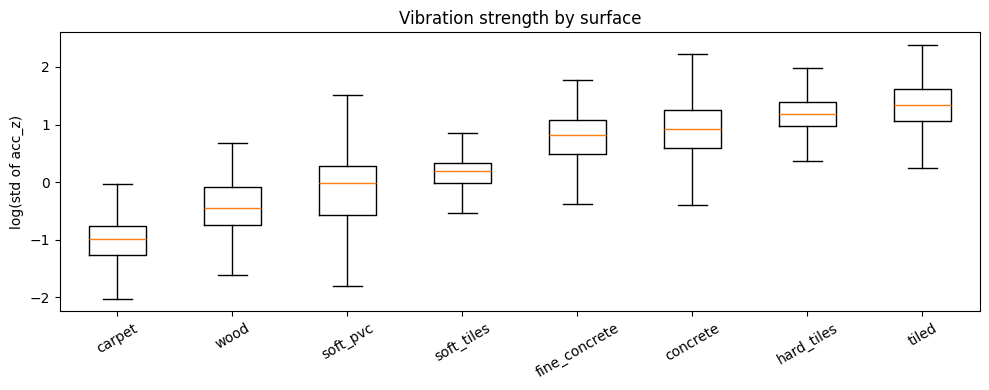

In [3]:
# 3. 특성 A(진동 세기) 계산 + 규칙에 쓸 값 확인
F = extract_features(X, 'A')
v = F['A_std_acc_z']
order = v.groupby(y).median().sort_values().index
plt.figure(figsize=(10, 4))
plt.boxplot([np.log(v[y == s]) for s in order], tick_labels=order, showfliers=False)
plt.ylabel('log(std of acc_z)'); plt.xticks(rotation=30); plt.title('Vibration strength by surface')
plt.tight_layout(); plt.show()

In [4]:
# 4. 녹화 하나 빼기 21-fold로 규칙 기준선 평가
pred = run_loro(RuleBaseline, F, y, rec)
m = evaluate(y, pred)
print({k: round(v, 4) for k, v in m.items()})
print('참고: 전부 딱딱한 바닥으로 찍기 정확도 =', round(np.mean([MODE[s] == 'hard' for s in y]), 3))

{'macro_f1': 0.351, 'accuracy': 0.3732, 'mode_macro_f1': 0.6663}
참고: 전부 딱딱한 바닥으로 찍기 정확도 = 0.663


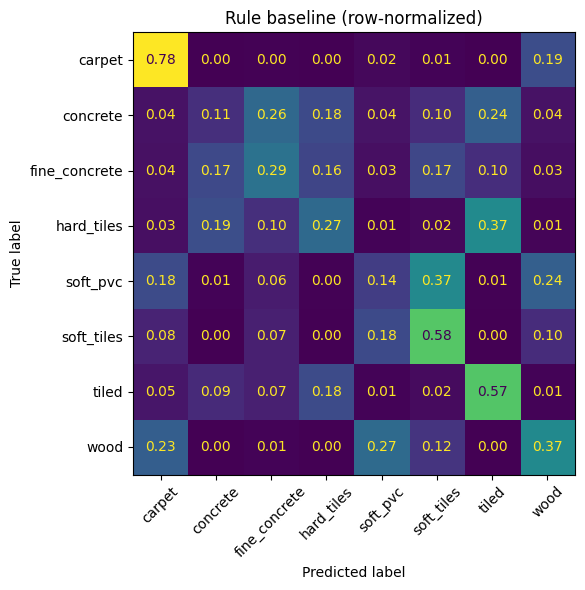

,surface,n,accuracy
rec,,,
13,soft_pvc,277,0.021661
5,soft_pvc,404,0.029703
4,concrete,219,0.041096
8,tiled,273,0.054945
19,concrete,360,0.061111
16,concrete,478,0.167364
0,hard_tiles,303,0.231023
6,hard_tiles,576,0.284722
9,fine_concrete,578,0.285467


In [5]:
# 5. 혼동행렬 + 녹화별 정확도
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=CLASSES, normalize='true',
                                        values_format='.2f', xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title('Rule baseline (row-normalized)'); plt.tight_layout(); plt.show()
per_recording_accuracy(y, pred, rec)

In [6]:
# 6. 전체 데이터로 맞춘 임계값 (발표·해석용, 평가에는 안 씀)
RuleBaseline().fit(F, y).thresholds()

,surface,center,upper_threshold
0,carpet,0.369134,0.486292
1,wood,0.640634,0.791427
2,soft_pvc,0.977715,1.088175
3,soft_tiles,1.211114,1.657814
4,fine_concrete,2.269272,2.385452
5,concrete,2.507581,2.870910
6,hard_tiles,3.286883,3.550909
7,tiled,3.836143,inf


In [7]:
# 7. 결과 기록 (results/results.csv에 한 줄 추가)
log_result('B', 'rule_baseline', m, note='log(acc_z std) 재질별 중앙값 최근접')
!tail -3 results/results.csv

date,owner,model,setting,fold,macro_f1,accuracy,mode_macro_f1,auroc,fpr95,note
2026-11-23,B,rule_baseline,8class,all,0.351,0.3732,0.6663,,,log(acc_z std) 재질별 중앙값 최근접


## 결과 메모

- macro-F1 / 정확도 / 모드 macro-F1:
- 잘 갈리는 재질:
- 헷갈리는 재질 쌍:
- wood 모드 오류: